# 07 · Manuscript figures (publication versions)

Standardised Earth-observation manuscript figures built from the existing analysis dataframes.

**Outputs:** `figures_v2/` — each figure as vector PDF (editable TrueType text) and 600-dpi PNG.

| File | Content |
|---|---|
| `01_overall_detection_performance` | Distribution of city-level F1 for vector and raster products |
| `02_complementary_quantity_metrics` | Area bias and building-count ratio |
| `03_f1_by_reference_source` | F1 stratified by reference-data provenance |
| `04_f1_by_settlement_morphology` | Tile-level F1 by building size and density classes |
| `05_vector_area_vs_count_ratio` | Supplementary: per-city vector area ratio vs count ratio |

**Design conventions (shared by all figures)**
- Drawn at final print size for a double-column width of 190 mm (7.5 in); fonts are 8.5–10 pt at that size.
- **Colour = product** (Okabe–Ito palette, colour-blind safe). **Fill = raster grid**: hatched boxes / open markers are 10 m, solid are 100 m.
- Box-plot anatomy (box = IQR, line = median, whiskers = 1.5 × IQR, dot = one city), the dashed perfect-agreement line and the off-scale arrows are explained in the figure captions, not in the figures.
- All annotated medians are computed from the plotted data, not hard-coded. The QC cell flags any drift from the manuscript table.

In [1]:
from google.colab import drive
import os, sys
from pathlib import Path
if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive')
else:
    print('Drive already mounted.')

# Linked project folder in Google Drive.
PROJECT_ROOT = Path('/content/drive/.shortcut-targets-by-id/1xTSKkjN4wft_0kljbwaAGKjTGEBsHZm1/Gates Foundation/Building Dataset Validation')
CONFIG_PATH = PROJECT_ROOT / 'configs' / 'validation_configs.yaml'
if not CONFIG_PATH.exists():
    raise FileNotFoundError(f'Config not found: {CONFIG_PATH}')
print(f'PROJECT_ROOT: {PROJECT_ROOT}')

# Code from GitHub, data from Drive (see colab_bootstrap.py in the repo).
# Drive PROJECT_ROOT/src is a stale hand-copy; never import from it.
import subprocess as _sp
_sp.run(['wget','-q','-O','/content/colab_bootstrap.py','https://raw.githubusercontent.com/GFDRR/urban_validation/fix/pipeline-audit/colab_bootstrap.py'], check=False)
sys.path.insert(0, '/content')
sys.modules.pop('colab_bootstrap', None); assert 'def setup' in open('/content/colab_bootstrap.py').read(), 'bootstrap download failed - check branch/URL'; from colab_bootstrap import setup as _setup
_setup(PROJECT_ROOT)   # clones repo -> sys.path; cwd stays on Drive

Drive already mounted.
PROJECT_ROOT: /content/drive/.shortcut-targets-by-id/1xTSKkjN4wft_0kljbwaAGKjTGEBsHZm1/Gates Foundation/Building Dataset Validation
code : /content/repo  @ fix/pipeline-audit (fa765ed)
src  : /content/repo/src/__init__.py
data : /content/drive/.shortcut-targets-by-id/1xTSKkjN4wft_0kljbwaAGKjTGEBsHZm1/Gates Foundation/Building Dataset Validation  (cwd)


PosixPath('/content/repo')

In [2]:
# Install plotting dependencies
import subprocess, sys
# kaleido 0.2.1 uses a bundled renderer — no Chrome needed, reliable in Colab
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "plotly", "kaleido==0.2.1"], check=False)

# Download Barlow font (optional — falls back to Arial if not available)
import os
try:
    os.system("wget -q -O /content/Barlow-Regular.ttf https://github.com/jpt/barlow/raw/main/fonts/ttf/Barlow-Regular.ttf || true")
    os.system("wget -q -O /content/BarlowSemiCondensed-Regular.ttf https://github.com/jpt/barlow/raw/main/fonts/ttf/BarlowSemiCondensed-Regular.ttf || true")
    import matplotlib.font_manager as _fm
    _fm.fontManager.addfont('/content/Barlow-Regular.ttf')
    _fm.fontManager.addfont('/content/BarlowSemiCondensed-Regular.ttf')
except Exception:
    pass

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
pio.kaleido.scope.mathjax = None  # avoid the 'Loading [MathJax]' box in Kaleido PDF exports
import pandas as pd
import numpy as np

FONT_FAMILY = 'Barlow, Arial, sans-serif'
FONT_COLOR  = '#1a1a1a'
BG_COLOR    = 'white'

from src.plots.style import DATASET_COLORS, DATASET_LABELS, apply_ppt_style_plotly as apply_ppt_style  # canonical - keep in sync via src/plots/style.py

# --- Canonical density / size classes (fixed; superseded per-subset quartiles 2026-07-22) ---
# Applied identically to vector AND raster so the two figure families are comparable.
# Building density (buildings per km2) — boundaries loosely aligned with the
# Degree of Urbanisation settlement hierarchy (UN Statistical Commission, 2020)
DENSITY_BREAKS = [0, 20, 100, 300, float('inf')]
DENSITY_LABELS = ['<20', '20–100', '100–300', '>300']
# Mean building footprint size (m2)
SIZE_BREAKS = [0, 80, 120, 180, float('inf')]
SIZE_LABELS = ['<80 m²', '80–120 m²', '120–180 m²', '>180 m²']

def save_fig(fig, name, outdir=None, width=None, height=None):
    """Save a Plotly figure as vector PDF (Overleaf/LaTeX) + high-res PNG (Docs/PPT)."""
    _dir = OUT_DIR if outdir is None else outdir
    fig.write_image(os.path.join(_dir, f'{name}.pdf'), width=width, height=height)
    fig.write_image(os.path.join(_dir, f'{name}.png'), width=width, height=height, scale=3)
SOURCE_COLORS = {
    'SpaceNet7':   '#E05C00',
    'HotOSM':      '#0072B2',
    'Other / Gov': '#009E73',
}


print('Setup complete.')


Setup complete.


In [3]:
# ── Derived paths from the resolved Gates Foundation project root ───────────
DATA_DIR = str(PROJECT_ROOT / 'outputs' / 'global_metrics') + '/'
OUT_DIR  = str(PROJECT_ROOT / 'figures_v2') + '/'
SENS_DIR = str(PROJECT_ROOT / 'outputs' / 'sensitivity_studies') + '/'
os.makedirs(OUT_DIR, exist_ok=True)
print(f'Figures will be saved to: {OUT_DIR}')

Figures will be saved to: /content/drive/.shortcut-targets-by-id/1xTSKkjN4wft_0kljbwaAGKjTGEBsHZm1/Gates Foundation/Building Dataset Validation/figures_v2/


In [4]:
vec = pd.read_csv(DATA_DIR + 'vector_all_cities_merged.csv')
ras = pd.read_csv(DATA_DIR + 'raster_all_cities_merged.csv')

# IoU threshold sensitivity (may not exist yet)
try:
    iou = pd.read_csv(SENS_DIR + 'iou_threshold_sensitivity.csv')
    print(f'iou: {len(iou)} rows')
except FileNotFoundError:
    iou = pd.DataFrame()
    print('iou: file not found — S1/S2 figures will be skipped')

# WSF year-sensitivity outputs
try:
    wsf_sweep   = pd.read_csv(SENS_DIR + 'wsf_year_sensitivity_summary.csv')
    wsf_aligned = pd.read_csv(SENS_DIR + 'wsf_temporal_alignment.csv')
    print(f'wsf_sweep: {len(wsf_sweep)} rows  |  wsf_aligned: {len(wsf_aligned)} rows')
except FileNotFoundError:
    wsf_sweep = pd.DataFrame()
    wsf_aligned = pd.DataFrame()
    print('WSF sensitivity CSVs not found — W1/W2 figures will be skipped')

# Build raster ds_key
ras['ds_key'] = ras['dataset'].astype(str).str.strip().str.lower() + '@' + ras['grid'].astype(str).str.strip().str.lower()

# Reference source classification for vector data
# Reference source classification — read from the AOI tracker (single source of
# truth: the same `source` column whose reference_source drives the IoU threshold
# in vector_runner). No hard-coded city lists, so split/new cities (e.g. *-sn7)
# are picked up automatically.
TRACKER = os.path.dirname(os.path.dirname(DATA_DIR.rstrip('/'))) + '/data/02_interim/aoi_tracker.csv'
_trk = pd.read_csv(TRACKER, dtype=str)
_trk.columns = _trk.columns.str.strip()
_SRC_LABEL = {'spacenet7': 'SpaceNet7', 'hotosm': 'HotOSM'}   # everything else -> Other / Gov
_trk['_city'] = _trk['dataset_folder_name'].astype(str).str.strip()
_trk['_src']  = _trk['source'].astype(str).str.strip().str.lower().map(_SRC_LABEL).fillna('Other / Gov')
_city_source = _trk.drop_duplicates('_city').set_index('_city')['_src']
vec['source'] = vec['city'].astype(str).str.strip().map(_city_source).fillna('Other / Gov')
print('Reference sources (from aoi_tracker.csv):')
print(vec.drop_duplicates('city')['source'].value_counts().to_string())

# Numeric coercion
for _c in ['f1_city','precision_city','recall_city','total_area_bias',
           'building_count_ratio','count_ratio_total','boundary_f_meanpair_tp']:
    if _c in vec.columns:
        vec[_c] = pd.to_numeric(vec[_c], errors='coerce')

for _c in ['f1_area','f1_tile_mean','signed_area_bias','rel_area_error_mean',
           'pred_building_count','ref_building_count']:
    if _c in ras.columns:
        ras[_c] = pd.to_numeric(ras[_c], errors='coerce')

print(f'vec: {len(vec)} rows, {vec["dataset"].nunique()} datasets, {vec["city"].nunique()} cities')
print(f'ras: {len(ras)} rows, {ras["ds_key"].nunique()} ds_keys, {ras["city"].nunique()} cities')
print(f'vec datasets: {sorted(vec["dataset"].unique())}')
print(f'ras ds_keys:  {sorted(ras["ds_key"].unique())}')

# ── Per-city metric columns — identical to 08_manuscript_summary_table ─────────
# Figures and the manuscript table must summarise the SAME per-city value:
#   vector F1          -> f1_city               (TP/FP/FN pooled over the city)
#   raster F1          -> f1_area               (area TP/FP/FN pooled over the city;
#                                                NOT f1_tile_mean = mean of tile F1s)
#   vector count ratio -> building_count_ratio  (pre-tiling cand / centroid ref count;
#                                                NOT count_ratio_total, which double-
#                                                counts buildings on tile edges)
#   raster count ratio -> count_ratio_est       (area-based proxy, see below)
#   area bias          -> total_area_bias (vector) / signed_area_bias (raster)
VEC_F1, RAS_F1 = 'f1_city', 'f1_area'
VEC_AREA_BIAS, RAS_AREA_BIAS = 'total_area_bias', 'signed_area_bias'
VEC_COUNT_RATIO, RAS_COUNT_RATIO = 'building_count_ratio', 'count_ratio_est'

# Raster products have no discrete building count: pred_building_count is
# pred_area / mean reference building size (src/plots/output.py::summarize_raster_city).
# Same formula as nb08 -> zero reference counts give inf, kept so medians match.
_missing = {'pred_building_count', 'ref_building_count'} - set(ras.columns)
if _missing:
    raise KeyError(f'raster_all_cities_merged.csv lacks {_missing}; re-run 04_aggregate_global_metrics.')
ras[RAS_COUNT_RATIO] = ras['pred_building_count'] / ras['ref_building_count']
_n_inf = int(np.isinf(ras[RAS_COUNT_RATIO]).sum())
print(f'raster count ratio: {ras[RAS_COUNT_RATIO].notna().sum()} city×product values'
      + (f' ({_n_inf} infinite: zero reference buildings)' if _n_inf else ''))


iou: 312 rows
wsf_sweep: 8 rows  |  wsf_aligned: 119 rows
Reference sources (from aoi_tracker.csv):
source
HotOSM         64
SpaceNet7      52
Other / Gov    19
vec: 401 rows, 3 datasets, 135 cities
ras: 724 rows, 6 ds_keys, 136 cities
vec datasets: ['gba', 'globfp', 'overture']
ras ds_keys:  ['ghsl_built_s_2025@100m', 'obt_2023@100m', 'obt_2023@10m', 'tempo_2023q4@100m', 'wsf_tracker@100m', 'wsf_tracker@10m']
raster count ratio: 724 city×product values


In [5]:
# ── Zero-F1 city exclusion (item 8b) ─────────────────────────────────────────
# Exclude cities where ALL datasets report F1 = 0. These are coverage failures or
# pipeline errors, NOT genuine zero-accuracy results, and they distort global means
# and error bars. Vector and raster are filtered SEPARATELY, each with its own
# criterion. Filtering is in-memory only — the raw CSV files are NOT modified.

# --- Vector: exclude a city if f1_city == 0 for overture AND gba AND globfp ---
VECTOR_FILTER_DATASETS = ['overture', 'gba', 'globfp']
_vpiv = (vec.assign(_ds=vec['dataset'].astype(str).str.strip().str.lower())
            .drop_duplicates(['city', '_ds'])
            .pivot(index='city', columns='_ds', values='f1_city')
            .reindex(columns=VECTOR_FILTER_DATASETS))
# A city is excluded only if all three datasets are present and every one is 0.
# (A missing dataset -> NaN -> NaN == 0 is False -> the city is kept.)
excluded_vec = sorted(_vpiv.index[(_vpiv == 0).all(axis=1)].tolist())
if excluded_vec:
    print(f"[vector] Excluding {len(excluded_vec)} cities (all datasets F1=0): {excluded_vec}")
else:
    print("[vector] No cities excluded (no city has all datasets F1=0).")
vec = vec[~vec['city'].isin(excluded_vec)]
print(f"[vector] Cities remaining: {vec['city'].nunique()}  ({len(vec)} rows)\n")

# --- Raster: exclude a city if F1 (RAS_F1) == 0 for all 6 ds_key values ---
RASTER_FILTER_DSKEYS = [
    'wsf_tracker@10m', 'obt_2023@10m', 'ghsl_built_s_2025@100m',
    'tempo_2023q4@100m', 'wsf_tracker@100m', 'obt_2023@100m',
]
_rpiv = (ras.drop_duplicates(['city', 'ds_key'])
            .pivot(index='city', columns='ds_key', values=RAS_F1)
            .reindex(columns=RASTER_FILTER_DSKEYS))
excluded_ras = sorted(_rpiv.index[(_rpiv == 0).all(axis=1)].tolist())
if excluded_ras:
    print(f"[raster] Excluding {len(excluded_ras)} cities (all datasets F1=0): {excluded_ras}")
else:
    print("[raster] No cities excluded (no city has all ds_keys F1=0).")
ras = ras[~ras['city'].isin(excluded_ras)]
print(f"[raster] Cities remaining: {ras['city'].nunique()}  ({len(ras)} rows)")

# --- Raster: exclude city × product COVERAGE GAPS (per product) ---
# A product that predicts no built-up pixels anywhere in a city's valid area
# (tp_total + fp_total == 0) has no coverage there: its pooled F1 is 0 by
# definition and its area bias is −1, but neither is an accuracy result.
# Drop that city × product row only; the city stays in for the other products.
# The same rule is applied in 08_manuscript_summary_table so table and figures match.
_gap = (ras['tp_total'] + ras['fp_total']) == 0
excluded_gaps = ras.loc[_gap, ['city', 'ds_key']].copy()
excluded_gaps['source'] = excluded_gaps['city'].astype(str).str.strip().map(_city_source).fillna('Other / Gov')
ras = ras[~_gap].copy()
print(f"\n[raster] Excluded {len(excluded_gaps)} city×product coverage gaps (no predicted built-up):")
if len(excluded_gaps):
    print(pd.crosstab(excluded_gaps['ds_key'], excluded_gaps['source']).to_string())

# Any remaining zero F1 is a genuine miss (built-up predicted, none matching the reference).
_real_zero = ras.loc[ras['f1_area'] == 0, ['city', 'ds_key', 'tp_total', 'fp_total', 'fn_total']]
if len(_real_zero):
    print(f"\n[raster] NOTE: {len(_real_zero)} city×product rows keep F1 = 0 (predictions exist, no overlap):")
    print(_real_zero.to_string(index=False))
print(f"[raster] Rows remaining: {len(ras)}")


[vector] No cities excluded (no city has all datasets F1=0).
[vector] Cities remaining: 135  (401 rows)

[raster] Excluding 2 cities (all datasets F1=0): ['jam-kingston-sn7', 'uga-kampala-sn7']
[raster] Cities remaining: 134  (712 rows)

[raster] Excluded 36 city×product coverage gaps (no predicted built-up):
source         HotOSM  Other / Gov  SpaceNet7
ds_key                                       
obt_2023@100m       5            9          4
obt_2023@10m        5            9          4
[raster] Rows remaining: 676


In [6]:
# ── Numerical QC against the manuscript summary table (08) ─────────────────
# Single source of truth: the table exported by 08_manuscript_summary_table.ipynb.
# Run 08 first (it applies the same coverage-gap exclusion as the cell above).
SUMMARY_TABLE = PROJECT_ROOT / 'outputs' / 'manuscript_tables' / 'summary_table.csv'
MEDIAN_TOLERANCE = 0.001  # same per-city values -> medians agree to rounding

# nb08 (Product, Representation) -> nb07 dataset / ds_key
NB08_KEYS = {
    ('Overture', 'Vector'): 'overture', ('GBA', 'Vector'): 'gba', ('3D-GloBFP', 'Vector'): 'globfp',
    ('OBT', 'Raster, 10 m'): 'obt_2023@10m', ('WSF Tracker', 'Raster, 10 m'): 'wsf_tracker@10m',
    ('OBT', 'Raster, 100 m'): 'obt_2023@100m', ('TEMPO', 'Raster, 100 m'): 'tempo_2023q4@100m',
    ('GHSL', 'Raster, 100 m'): 'ghsl_built_s_2025@100m', ('WSF Tracker', 'Raster, 100 m'): 'wsf_tracker@100m',
}
QC_METRICS = {  # nb08 column -> (vector column, raster column)
    'F1 (median)':                 (VEC_F1, RAS_F1),
    'Relative area bias (median)': (VEC_AREA_BIAS, RAS_AREA_BIAS),
    'Count ratio (median)':        (VEC_COUNT_RATIO, RAS_COUNT_RATIO),
}
if not SUMMARY_TABLE.exists():
    raise FileNotFoundError(f'{SUMMARY_TABLE} not found — run 08_manuscript_summary_table.ipynb first.')
_tbl = pd.read_csv(SUMMARY_TABLE)
_tbl['key'] = [NB08_KEYS.get((p, r)) for p, r in zip(_tbl['Product'], _tbl['Representation'])]
_tbl = _tbl.dropna(subset=['key']).set_index('key')
expected = {m: _tbl[m].to_dict() for m in QC_METRICS}
print(f'QC reference: {SUMMARY_TABLE}')

qc_rows = []
for metric, (vec_col, ras_col) in QC_METRICS.items():
    actual = {**vec.groupby('dataset')[vec_col].median().to_dict(),
              **ras.groupby('ds_key')[ras_col].median().to_dict()}
    for key, target in expected[metric].items():
        value = actual.get(key, np.nan)
        qc_rows.append({'metric': metric.replace(' (median)', ''), 'product': key,
                        'nb07': value, 'nb08': target, 'delta': value - target})
qc_table = pd.DataFrame(qc_rows)
qc_table['status'] = np.where(qc_table['delta'].abs() <= MEDIAN_TOLERANCE, 'OK', 'WARNING')
print(qc_table.to_string(index=False, float_format='{:.3f}'.format))
n_warn = int((qc_table['status'] == 'WARNING').sum())
print(f"\nQC: {len(qc_table) - n_warn}/{len(qc_table)} medians match the manuscript table."
      + ('' if not n_warn else ' Resolve WARNINGs before exporting figures.'))


QC reference: /content/drive/.shortcut-targets-by-id/1xTSKkjN4wft_0kljbwaAGKjTGEBsHZm1/Gates Foundation/Building Dataset Validation/outputs/manuscript_tables/summary_table.csv
            metric                product   nb07   nb08  delta status
                F1               overture  0.786  0.786  0.000     OK
                F1                    gba  0.564  0.564  0.000     OK
                F1                 globfp  0.458  0.458  0.000     OK
                F1           obt_2023@10m  0.680  0.680  0.000     OK
                F1        wsf_tracker@10m  0.568  0.568  0.000     OK
                F1          obt_2023@100m  0.782  0.782  0.000     OK
                F1       wsf_tracker@100m  0.904  0.904 -0.000     OK
                F1      tempo_2023q4@100m  0.821  0.821  0.000     OK
                F1 ghsl_built_s_2025@100m  0.813  0.813  0.000     OK
Relative area bias               overture  0.093  0.093  0.000     OK
Relative area bias                    gba  0.124  0.12

## Shared figure style and helpers

In [7]:
# ── Publication style, product encodings and shared plotting helpers ────────
# Target: Elsevier double-column width (190 mm ≈ 7.5 in). Figures are drawn at
# final print size, so font sizes below are the sizes that appear in the paper.
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

FIG_WIDTH = 7.5  # inches; full text width
PANEL_TITLE_SIZE = 11.5  # panel letter + subplot title

VECTOR_ORDER = ["overture", "gba", "globfp"]
VECTOR_LABELS = {"overture": "Overture Maps", "gba": "GBA", "globfp": "3D-GloBFP"}
VECTOR_COLORS = {"overture": "#0072B2", "gba": "#009E73", "globfp": "#56B4E9"}

RASTER_ORDER = [
    "obt_2023@10m", "wsf_tracker@10m", "obt_2023@100m",
    "tempo_2023q4@100m", "ghsl_built_s_2025@100m", "wsf_tracker@100m",
]
RASTER_PRODUCT_LABELS = {
    "obt_2023": "OBT", "wsf_tracker": "WSF Tracker",
    "tempo_2023q4": "TEMPO", "ghsl_built_s_2025": "GHSL",
}
RASTER_COLORS = {
    "obt_2023": "#E69F00", "wsf_tracker": "#D55E00",
    "tempo_2023q4": "#7B3294", "ghsl_built_s_2025": "#CC79A7",
}
# Product identity = colour; grid resolution = fill (10 m hatched/open, 100 m solid).
HATCH_10M = "////"

SOURCE_ALIASES = {
    "SpaceNet7": "SpaceNet 7", "HotOSM": "HOTOSM",
    "Other / Gov": "Other institutional / government",
}
SOURCE_ORDER = ["SpaceNet 7", "HOTOSM", "Other institutional / government"]

INK, INK_MUTED, GRID, SPINE = "#1a1a1a", "#555555", "#E6E6E6", "#8C8C8C"
POINT_COLOR = "#4D4D4D"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
    "font.size": 9, "axes.titlesize": 11.5, "axes.labelsize": 9,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5, "legend.title_fontsize": 8.5,
    "text.color": INK, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "hatch.linewidth": 0.6,
    "pdf.fonttype": 42, "ps.fonttype": 42,  # editable TrueType text in PDF
    "savefig.dpi": 600, "figure.dpi": 110,
})


def is_raster(key):
    return "@" in key


def grid_of(ds_key):
    return ds_key.split("@")[1].replace("m", " m")


def product_color(key):
    return RASTER_COLORS[key.split("@")[0]] if is_raster(key) else VECTOR_COLORS[key]


def product_label(key, with_grid=True):
    if not is_raster(key):
        return VECTOR_LABELS[key]
    name = RASTER_PRODUCT_LABELS[key.split("@")[0]]
    return f"{name} ({grid_of(key)})" if with_grid else name


def product_patch(key, label=None):
    """Legend swatch matching the box styling (hatched = 10 m raster)."""
    color = product_color(key)
    hatched = is_raster(key) and key.endswith("@10m")
    return Patch(facecolor=mpl.colors.to_rgba(color, 0.55), edgecolor=color,
                 hatch=HATCH_10M if hatched else None, linewidth=0.9,
                 label=label or product_label(key))


def save_publication_figure(fig, name):
    path = Path(OUT_DIR)
    path.mkdir(parents=True, exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(path / f"{name}.{ext}", dpi=600, bbox_inches="tight",
                    pad_inches=0.04, facecolor="white")
    print(f"Saved {name}.pdf/.png to {path}")


def panel_header(ax, label, title, pad_pt=6):
    """Panel letter + title (both regular weight), chained so they can never overlap."""
    letter = ax.text(0, 1, label, transform=ax.transAxes + mtransforms.ScaledTranslation(
        0, pad_pt / 72, ax.figure.dpi_scale_trans), ha="left", va="bottom",
        fontsize=PANEL_TITLE_SIZE)
    ax.annotate(title, xy=(1, 0), xycoords=letter, xytext=(4, 0),
                textcoords="offset points", ha="left", va="bottom", fontsize=PANEL_TITLE_SIZE)


def median_row(ax, positions, samples, fmt="{:.3f}"):
    """Row of median values just above the plot area, aligned with each box."""
    trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    for position, sample in zip(positions, samples):
        ax.text(position, 1.03, fmt.format(np.median(sample)), transform=trans, ha="center",
                va="bottom", fontsize=8.5, fontweight="bold", color=INK)
    ax.text(0, 1.03, "Median", transform=ax.transAxes + mtransforms.ScaledTranslation(
        -6 / 72, 0, ax.figure.dpi_scale_trans), ha="right", va="bottom", fontsize=8.5,
        fontstyle="italic", color=INK_MUTED)


# Matplotlib ≥ 3.10 replaces boxplot(vert=False) with orientation="horizontal".
HORIZONTAL_BOX = ({"orientation": "horizontal"}
                  if tuple(int(v) for v in mpl.__version__.split(".")[:2]) >= (3, 10) else {"vert": False})


def clean_axis(ax, grid_axis="y"):
    ax.set_axisbelow(True)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(SPINE)
    ax.tick_params(colors=INK, length=3)


def style_boxes(bp, keys):
    for patch, key in zip(bp["boxes"], keys):
        color = product_color(key)
        patch.set_facecolor(mpl.colors.to_rgba(color, 0.55))
        patch.set_edgecolor(color); patch.set_linewidth(1.0)
        if is_raster(key) and key.endswith("@10m"):
            patch.set_hatch(HATCH_10M)
    for element in ("whiskers", "caps"):
        for line in bp[element]:
            line.set_color(INK_MUTED); line.set_linewidth(0.8)
    for line in bp["medians"]:
        line.set_color(INK); line.set_linewidth(1.6)


def jitter_points(ax, positions, samples, vertical=True, width=0.13, size=6):
    rng = np.random.default_rng(20261005)
    for position, sample in zip(positions, samples):
        jitter = position + rng.uniform(-width, width, len(sample))
        xy = (jitter, sample) if vertical else (sample, jitter)
        ax.scatter(*xy, s=size, color=POINT_COLOR, alpha=0.35, linewidths=0, zorder=3)


def resolution_brackets(ax, groups, y=-0.24):
    """Draw '10 m grid' / '100 m grid' brackets beneath the x tick labels."""
    trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    for start, end, text in groups:
        ax.plot([start - 0.35, end + 0.35], [y, y], color=INK_MUTED, linewidth=0.8,
                transform=trans, clip_on=False)
        for x in (start - 0.35, end + 0.35):
            ax.plot([x, x], [y, y + 0.025], color=INK_MUTED, linewidth=0.8,
                    transform=trans, clip_on=False)
        ax.text((start + end) / 2, y - 0.02, text, transform=trans, ha="center", va="top",
                fontsize=8.5, fontweight="bold", color=INK_MUTED)


# Reference-source labels used in Figure 3 (vector and raster share the AOI tracker).
source_vec = vec.assign(source_label=vec["source"].map(SOURCE_ALIASES))
source_ras = ras.assign(source_label=ras["city"].astype(str).str.strip()
                        .map(_city_source).fillna("Other / Gov").map(SOURCE_ALIASES))
print("Style and helpers ready.")

Style and helpers ready.


In [8]:
# ── Tile-level morphology inputs for Figure 4 ──────────────────────────────
# Reusable morphology inputs from the existing enrichment outputs.
_TILE_CSV = Path(os.path.dirname(DATA_DIR.rstrip("/"))) / "scratch" / "per_tile_enriched_all_cities.csv"
# Uses the canonical DENSITY_/SIZE_ BREAKS & LABELS defined in the setup cell.

tile = pd.read_csv(_TILE_CSV)
tile["dataset"] = tile["dataset"].astype(str).str.lower()
for column in ["f1", "ref_building_density_per_km2", "mean_ref_building_area_m2", "ref_building_count_centroid"]:
    tile[column] = pd.to_numeric(tile[column], errors="coerce")
tile = tile[tile["dataset"].isin(VECTOR_ORDER)].dropna(subset=["f1", "ref_building_density_per_km2", "mean_ref_building_area_m2"])
tile = tile[(tile["ref_building_count_centroid"] > 0) & (tile["ref_building_density_per_km2"] > 0) & (tile["mean_ref_building_area_m2"] > 0)].copy()
tile["density_class"] = pd.cut(tile["ref_building_density_per_km2"], DENSITY_BREAKS, labels=DENSITY_LABELS, include_lowest=True)
tile["size_class"] = pd.cut(tile["mean_ref_building_area_m2"], SIZE_BREAKS, labels=SIZE_LABELS, include_lowest=True)

metrics_dir = Path(PROJECT_ROOT) / "outputs" / "metrics"
density_lookup = tile[["city", "tile_id", "ref_building_density_per_km2", "mean_ref_building_area_m2", "ref_building_count_centroid"]].drop_duplicates(["city", "tile_id"])
raster_parts = []
for parquet in sorted(metrics_dir.rglob("raster_metrics_tiles_all_datasets.parquet")):
    try: raster_parts.append(pd.read_parquet(parquet, columns=["city", "tile_id", "dataset", "grid", "f1"]))
    except Exception as error: print(f"Skipping {parquet}: {error}")
rtile = pd.concat(raster_parts, ignore_index=True) if raster_parts else pd.DataFrame()
if not rtile.empty:
    rtile["ds_key"] = rtile["dataset"].astype(str).str.lower() + "@" + rtile["grid"].astype(str).str.lower()
    rtile = rtile[rtile["ds_key"].isin(RASTER_ORDER)].merge(density_lookup, on=["city", "tile_id"], how="left")
    rtile = rtile.dropna(subset=["f1", "ref_building_density_per_km2", "mean_ref_building_area_m2"])
    rtile = rtile[rtile["ref_building_count_centroid"] > 0].copy()
    rtile["density_class"] = pd.cut(rtile["ref_building_density_per_km2"], DENSITY_BREAKS, labels=DENSITY_LABELS, include_lowest=True)
    rtile["size_class"] = pd.cut(rtile["mean_ref_building_area_m2"], SIZE_BREAKS, labels=SIZE_LABELS, include_lowest=True)
print(f"Vector tiles: {len(tile):,} | raster tiles: {len(rtile):,}")

Vector tiles: 30,258 | raster tiles: 44,537


## Figure 1 · Overall detection performance
Box plots of city-level F1 for (a) vector footprint products and (b) raster built-up products, with raster products grouped by grid resolution. Medians appear in the row above each panel.

Saved 01_overall_detection_performance.pdf/.png to /content/drive/.shortcut-targets-by-id/1xTSKkjN4wft_0kljbwaAGKjTGEBsHZm1/Gates Foundation/Building Dataset Validation/figures_v2


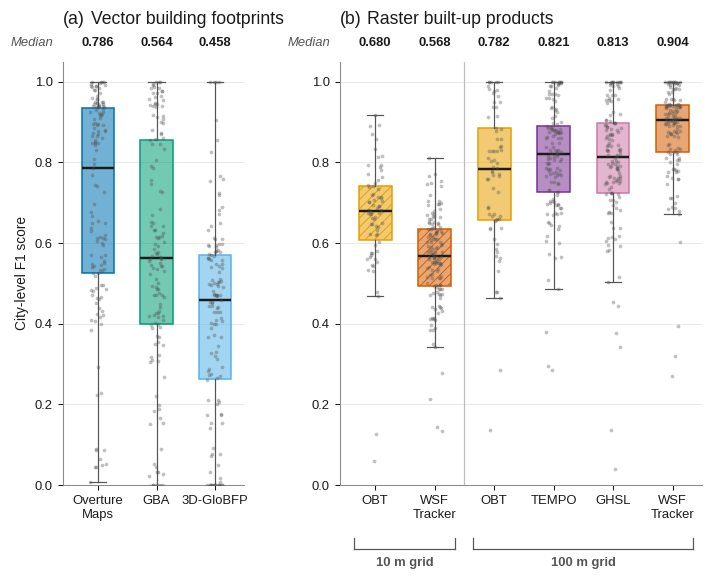

In [9]:
# ── Figure 1 · Overall detection performance ────────────────────────────────
def vertical_boxes(ax, frame, value_col, keys, key_col):
    samples = [frame.loc[frame[key_col] == k, value_col].dropna().to_numpy(float) for k in keys]
    positions = np.arange(1, len(keys) + 1)
    bp = ax.boxplot(samples, positions=positions, widths=0.55, patch_artist=True, showfliers=False)
    style_boxes(bp, keys)
    jitter_points(ax, positions, samples)
    return positions, samples


fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, 5.0),
                         gridspec_kw={"width_ratios": [3, 6], "wspace": 0.35})

ax = axes[0]
pos, samples = vertical_boxes(ax, vec, VEC_F1, VECTOR_ORDER, "dataset")
ax.set_xticks(pos, ["Overture\nMaps", "GBA", "3D-GloBFP"])
median_row(ax, pos, samples)
ax.set_ylabel("City-level F1 score")
panel_header(ax, "(a)", "Vector building footprints", pad_pt=22)

ax = axes[1]
pos, samples = vertical_boxes(ax, ras, RAS_F1, RASTER_ORDER, "ds_key")
ax.set_xticks(pos, [product_label(k, False).replace(" ", "\n") for k in RASTER_ORDER])
median_row(ax, pos, samples)
ax.axvline(2.5, color="#BDBDBD", linewidth=0.8)
# ax.set_ylabel("City-level F1 score")
panel_header(ax, "(b)", "Raster built-up products", pad_pt=22)
resolution_brackets(ax, [(1, 2, "10 m grid"), (3, 6, "100 m grid")], y=-0.15)

for ax in axes:
    ax.set_ylim(0, 1.05); ax.set_yticks(np.arange(0, 1.05, 0.2)); ax.set_xlim(0.4, ax.get_xlim()[1])
    clean_axis(ax, "y")

save_publication_figure(fig, "01_overall_detection_performance"); plt.show()

## Figure 2 · Complementary quantity agreement
(a) Relative building-area bias and (b) building-count ratio for vector products; (c) relative built-up area bias and (d) estimated building-count ratio for raster products. The raster count is an area-based proxy (predicted built-up area ÷ mean reference building size), marked * as in the manuscript table. Box-plot statistics use the full sample, including cities beyond the axis limits.

Saved 02_complementary_quantity_metrics.pdf/.png to /content/drive/.shortcut-targets-by-id/1xTSKkjN4wft_0kljbwaAGKjTGEBsHZm1/Gates Foundation/Building Dataset Validation/figures_v2


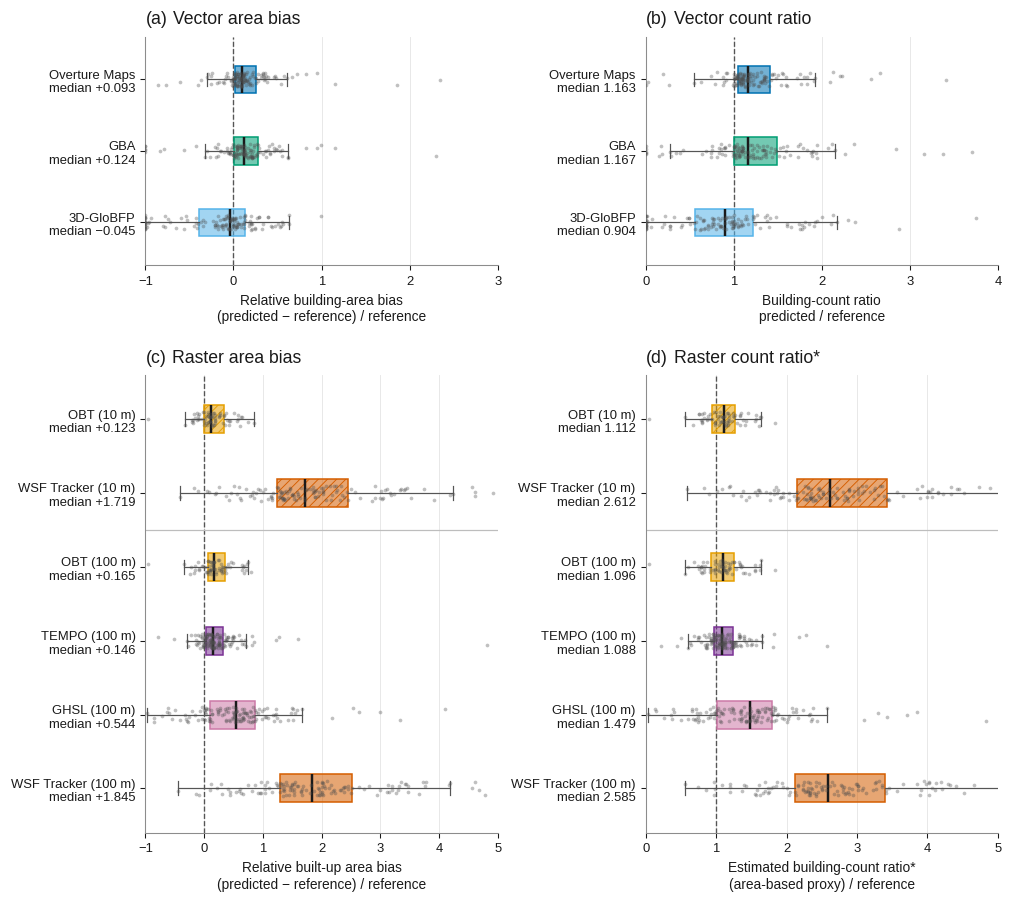

In [10]:
# ── Figure 2 · Complementary quantity agreement (area bias, count ratio) ────
def horizontal_boxes(ax, frame, value_col, keys, key_col, xlim, reference):
    """Horizontal box plots on the FULL sample (statistics include cities beyond the axis limits)."""
    samples = [frame.loc[frame[key_col] == k, value_col].dropna().to_numpy(float) for k in keys]
    # ±inf (e.g. count ratio with zero reference buildings) stays in the sample as an
    # extreme value, so medians/quartiles match nb08 (it falls outside the plotted range).
    samples = [np.nan_to_num(s, posinf=1e12, neginf=-1e12) for s in samples]
    positions = np.arange(1, len(keys) + 1)
    bp = ax.boxplot(samples, positions=positions, widths=0.38, patch_artist=True, showfliers=False, **HORIZONTAL_BOX)
    style_boxes(bp, keys)
    xmin, xmax = xlim
    jitter_points(ax, positions, [s[(s >= xmin) & (s <= xmax)] for s in samples], vertical=False, width=0.1)
    ax.axvline(reference, color=INK_MUTED, linewidth=0.9, linestyle="--", zorder=1)
    fmt = "{:.3f}" if reference == 1 else "{:+.3f}"  # signed for biases, plain for ratios
    ax.set_yticks(positions, [f"{product_label(k)}\nmedian {fmt.format(np.median(s)).replace('-', '−')}"
                              for k, s in zip(keys, samples)])
    ax.set_xlim(*xlim); ax.set_ylim(len(keys) + 0.6, 0.4)
    clean_axis(ax, "x")


# Wider than FIG_WIDTH for larger panels; scale to text width on import.
fig = plt.figure(figsize=(10.0, 9.4))
gs = fig.add_gridspec(2, 2, height_ratios=[3, 6], hspace=0.32, wspace=0.42)
ax_a, ax_b = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
ax_c, ax_d = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])

horizontal_boxes(ax_a, vec, VEC_AREA_BIAS, VECTOR_ORDER, "dataset", (-1, 3), 0)
ax_a.set_xlabel("Relative building-area bias\n(predicted − reference) / reference")
panel_header(ax_a, "(a)", "Vector area bias")

horizontal_boxes(ax_b, vec, VEC_COUNT_RATIO, VECTOR_ORDER, "dataset", (0, 4), 1)
ax_b.set_xlabel("Building-count ratio\npredicted / reference")
panel_header(ax_b, "(b)", "Vector count ratio")

horizontal_boxes(ax_c, ras, RAS_AREA_BIAS, RASTER_ORDER, "ds_key", (-1, 5), 0)
ax_c.set_xlabel("Relative built-up area bias\n(predicted − reference) / reference")
panel_header(ax_c, "(c)", "Raster area bias")

# Raster count = predicted built-up area / mean reference building size (proxy; * in nb08).
horizontal_boxes(ax_d, ras, RAS_COUNT_RATIO, RASTER_ORDER, "ds_key", (0, 5), 1)
ax_d.set_xlabel("Estimated building-count ratio*\n(area-based proxy) / reference")
panel_header(ax_d, "(d)", "Raster count ratio*")

for ax in (ax_c, ax_d):
    ax.axhline(2.5, color="#BDBDBD", linewidth=0.8)
# Whole-number ticks on every panel for a consistent scale.
for ax, (lo, hi) in [(ax_a, (-1, 3)), (ax_b, (0, 4)), (ax_c, (-1, 5)), (ax_d, (0, 5))]:
    ax.set_xticks(np.arange(lo, hi + 1))

save_publication_figure(fig, "02_complementary_quantity_metrics"); plt.show()

## Figure 3 · F1 by reference-data source
City-level F1 stratified by reference provenance (SpaceNet 7, HOTOSM, other institutional / government). Group labels give the number of cities.

Saved 03_f1_by_reference_source.pdf/.png to /content/drive/.shortcut-targets-by-id/1xTSKkjN4wft_0kljbwaAGKjTGEBsHZm1/Gates Foundation/Building Dataset Validation/figures_v2


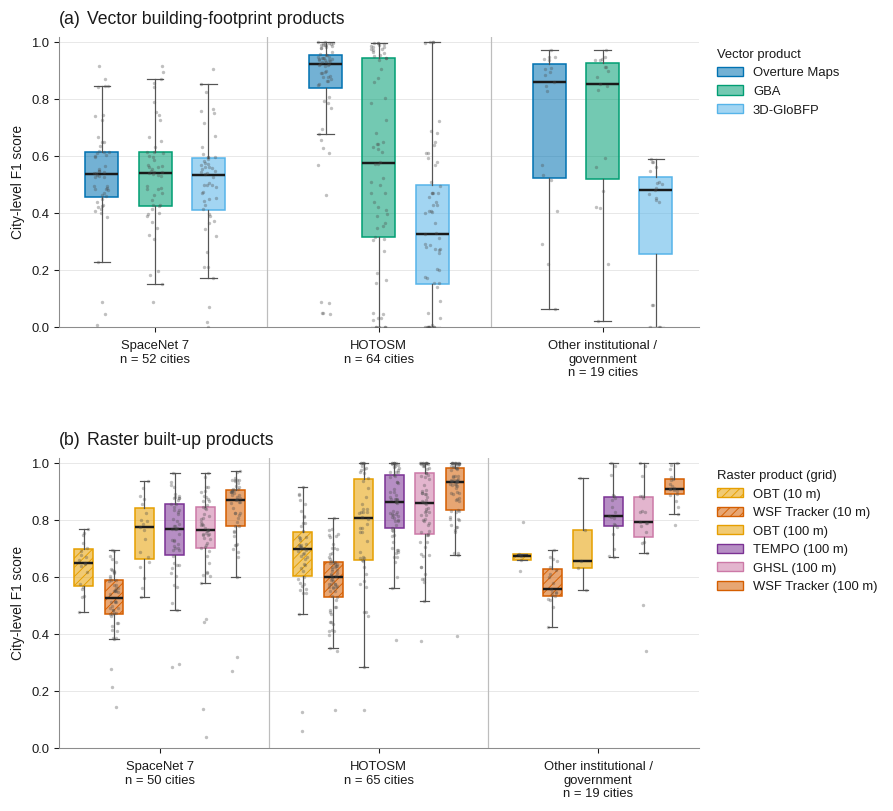

In [11]:
# ── Figure 3 · F1 stratified by reference-data source ───────────────────────
def source_panel(ax, frame, value_col, keys, key_col):
    group_width = len(keys) + 1.2
    centers, tick_labels = [], []
    for g, source in enumerate(SOURCE_ORDER):
        in_source = frame[frame["source_label"] == source]
        positions = g * group_width + np.arange(len(keys))
        samples = [in_source.loc[in_source[key_col] == k, value_col].dropna().to_numpy(float) for k in keys]
        present = [i for i, s in enumerate(samples) if len(s)]
        bp = ax.boxplot([samples[i] for i in present], positions=positions[present], widths=0.62,
                        patch_artist=True, showfliers=False)
        style_boxes(bp, [keys[i] for i in present])
        jitter_points(ax, positions[present], [samples[i] for i in present], width=0.15, size=5)
        if g:
            ax.axvline(positions[0] - 1.1, color="#BDBDBD", linewidth=0.8)
        centers.append(positions.mean())
        name = source.replace(" / ", " /\n")
        tick_labels.append(f"{name}\nn = {in_source['city'].nunique()} cities")
    ax.set_xticks(centers, tick_labels)
    ax.tick_params(axis="x", length=0, pad=5)
    ax.set_xlim(-0.8, (len(SOURCE_ORDER) - 1) * group_width + len(keys) - 0.2)
    ax.set_ylim(0, 1.02); ax.set_yticks(np.arange(0, 1.01, 0.2))
    clean_axis(ax, "y")


fig, axes = plt.subplots(2, 1, figsize=(FIG_WIDTH, 8.4), gridspec_kw={"hspace": 0.45})

source_panel(axes[0], source_vec, VEC_F1, VECTOR_ORDER, "dataset")
axes[0].set_ylabel("City-level F1 score")
panel_header(axes[0], "(a)", "Vector building-footprint products")
axes[0].legend(handles=[product_patch(k) for k in VECTOR_ORDER], title="Vector product",
               loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, alignment="left")

source_panel(axes[1], source_ras, RAS_F1, RASTER_ORDER, "ds_key")
axes[1].set_ylabel("City-level F1 score")
panel_header(axes[1], "(b)", "Raster built-up products")
axes[1].legend(handles=[product_patch(k) for k in RASTER_ORDER], title="Raster product (grid)",
               loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, alignment="left")

save_publication_figure(fig, "03_f1_by_reference_source"); plt.show()

## Figure 4 · F1 by settlement morphology
Median (marker) and interquartile range (bar) of tile-level F1 across classes of mean reference building size (top row) and reference building density (bottom row). Vector products are on the left, raster products on the right.

Saved 04_f1_by_settlement_morphology.pdf/.png to /content/drive/.shortcut-targets-by-id/1xTSKkjN4wft_0kljbwaAGKjTGEBsHZm1/Gates Foundation/Building Dataset Validation/figures_v2


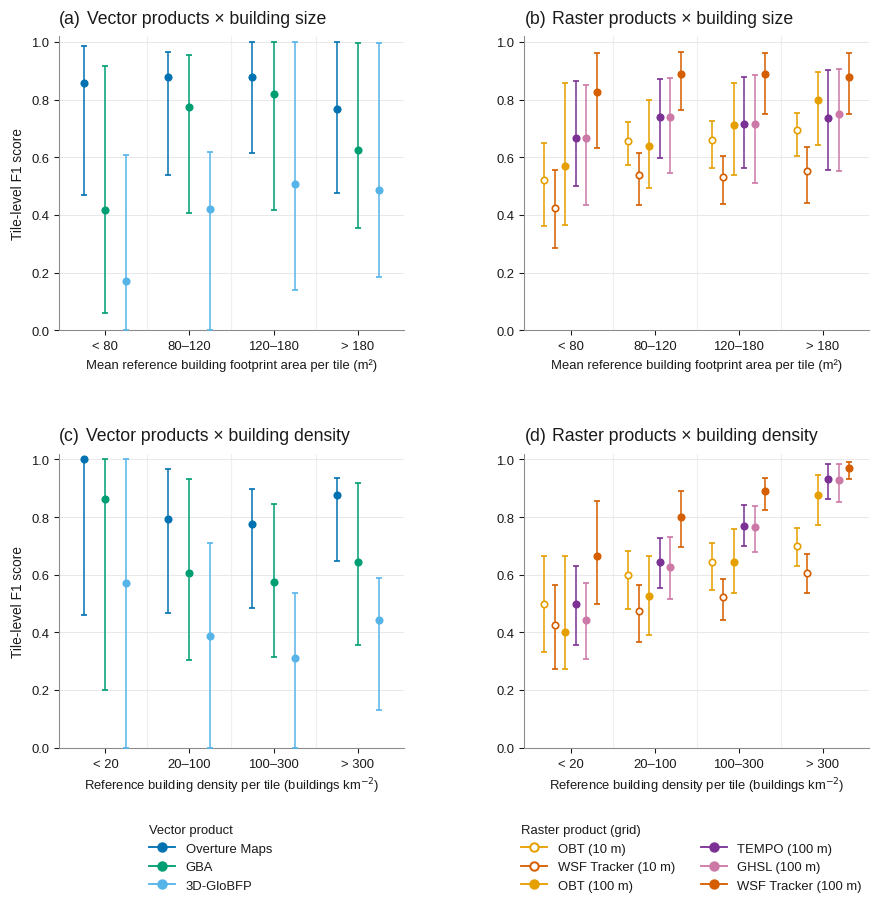

In [12]:
# ── Figure 4 · F1 by settlement morphology (median ± IQR across tiles) ──────
def morphology_panel(ax, frame, class_col, class_order, keys, key_col):
    # Equal sub-slots across 75 % of each class width, leaving a clear gap at the class dividers (±0.5).
    slot = 0.75 / len(keys)
    offsets = (np.arange(len(keys)) - (len(keys) - 1) / 2) * slot
    for key, offset in zip(keys, offsets):
        grouped = frame[frame[key_col] == key].groupby(class_col, observed=False)["f1"]
        med = grouped.median().reindex(class_order)
        q1 = grouped.quantile(0.25).reindex(class_order)
        q3 = grouped.quantile(0.75).reindex(class_order)
        valid = med.notna().to_numpy()
        x = np.arange(len(class_order))[valid] + offset
        color = product_color(key)
        open_marker = is_raster(key) and key.endswith("@10m")
        ax.errorbar(x, med[valid], yerr=[med[valid] - q1[valid], q3[valid] - med[valid]],
                    fmt="o", markersize=4.2, elinewidth=1.0, capsize=1.8, capthick=0.9,
                    color=color, markerfacecolor="white" if open_marker else color,
                    markeredgecolor=color, markeredgewidth=1.1, zorder=3)
    for boundary in np.arange(0.5, len(class_order) - 1, 1):
        ax.axvline(boundary, color="#EFEFEF", linewidth=0.8, zorder=0)
    ax.set_xticks(np.arange(len(class_order)), class_order)
    ax.set_xlim(-0.55, len(class_order) - 0.45)
    ax.set_ylim(0, 1.02); ax.set_yticks(np.arange(0, 1.01, 0.2))
    clean_axis(ax, "y")


def morphology_handle(key):
    color = product_color(key)
    open_marker = is_raster(key) and key.endswith("@10m")
    return Line2D([], [], marker="o", markersize=5.5, linestyle="-", linewidth=1.2, color=color,
                  markerfacecolor="white" if open_marker else color, markeredgewidth=1.3,
                  label=product_label(key))


SIZE_AXIS = "Mean reference building footprint area per tile (m²)"
DENSITY_AXIS = "Reference building density per tile (buildings km$^{-2}$)"
DENSITY_TICKS = ["< 20", "20–100", "100–300", "> 300"]
SIZE_TICKS = ["< 80", "80–120", "120–180", "> 180"]

# Wider than FIG_WIDTH so each class slot has room for its products; scale to text width on import.
fig, axes = plt.subplots(2, 2, figsize=(9.5, 8.4), sharey=True,
                         gridspec_kw={"hspace": 0.42, "wspace": 0.35})
panels = [
    (axes[0, 0], tile, "size_class", SIZE_LABELS, VECTOR_ORDER, "dataset", "(a)", "Vector products × building size", SIZE_AXIS, SIZE_TICKS),
    (axes[0, 1], rtile, "size_class", SIZE_LABELS, RASTER_ORDER, "ds_key", "(b)", "Raster products × building size", SIZE_AXIS, SIZE_TICKS),
    (axes[1, 0], tile, "density_class", DENSITY_LABELS, VECTOR_ORDER, "dataset", "(c)", "Vector products × building density", DENSITY_AXIS, DENSITY_TICKS),
    (axes[1, 1], rtile, "density_class", DENSITY_LABELS, RASTER_ORDER, "ds_key", "(d)", "Raster products × building density", DENSITY_AXIS, DENSITY_TICKS),
]
for ax, frame, class_col, order, keys, key_col, letter, title, xlabel, ticks in panels:
    morphology_panel(ax, frame, class_col, order, keys, key_col)
    ax.set_xticklabels(ticks); ax.set_xlabel(xlabel, fontsize=8.5)
    panel_header(ax, letter, title)
for ax in axes[:, 0]:
    ax.set_ylabel("Tile-level F1 score")
for ax in axes[:, 1]:
    ax.tick_params(axis="y", labelleft=True)

fig.legend(handles=[morphology_handle(k) for k in VECTOR_ORDER], title="Vector product",
           loc="upper center", bbox_to_anchor=(0.27, 0.04), ncol=1, frameon=False, alignment="left")
fig.legend(handles=[morphology_handle(k) for k in RASTER_ORDER], title="Raster product (grid)",
           loc="upper center", bbox_to_anchor=(0.73, 0.04), ncol=2, frameon=False, alignment="left")
save_publication_figure(fig, "04_f1_by_settlement_morphology"); plt.show()

## Figure 5 (supplementary) · Vector area ratio vs count ratio per city
One point per city. The x-axis is the building-count ratio and the y-axis is the building-area ratio (1 + relative area bias), both predicted / reference on log scales, so over- and under-estimation are symmetric. Dashed lines mark perfect agreement. Along the dotted diagonal, the mean predicted building size equals the mean reference building size. Corners: **more and larger** (top right) means extra structures; **fewer and smaller** (bottom left) means missed buildings; **more but smaller** (bottom right) means footprints split into fragments; **fewer but larger** (top left) means adjacent buildings merged. The cross marks the product's median city.

Figure 5: 19 city×product rows without a positive finite ratio are not plotted.
Figure 5 axis range: 1/32 – 32  (12 city×product points beyond it)
Saved 05_vector_area_vs_count_ratio.pdf/.png to /content/drive/.shortcut-targets-by-id/1xTSKkjN4wft_0kljbwaAGKjTGEBsHZm1/Gates Foundation/Building Dataset Validation/figures_v2


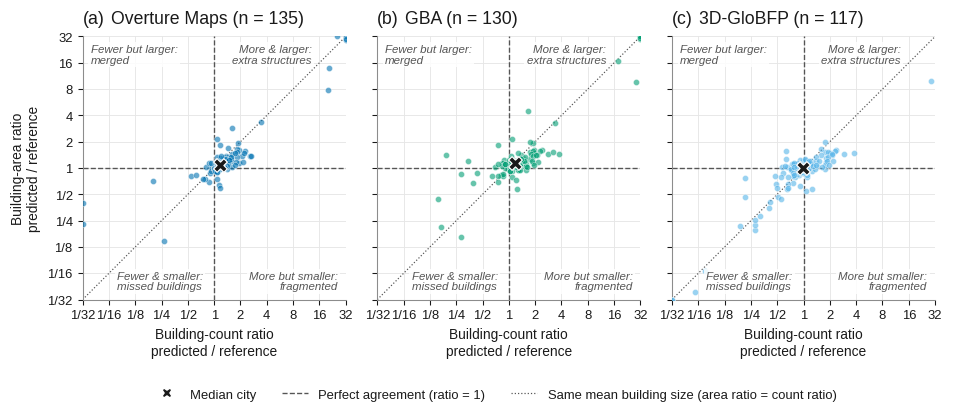

In [13]:
# ── Figure 5 (supplementary) · Vector area ratio vs count ratio per city ────
area_ratio = 1 + vec[VEC_AREA_BIAS]          # predicted / reference building area
count_ratio = vec[VEC_COUNT_RATIO]           # predicted / reference building count
scatter_df = vec.assign(area_ratio=area_ratio, count_ratio=count_ratio)
_valid = (scatter_df["area_ratio"] > 0) & (scatter_df["count_ratio"] > 0) & np.isfinite(scatter_df["count_ratio"])
if (~_valid).any():
    print(f"Figure 5: {int((~_valid).sum())} city×product rows without a positive finite ratio are not plotted.")
scatter_df = scatter_df[_valid]

# Symmetric log2 limits covering 99 % of cities (power of two, at most ×32).
_extent = np.nanpercentile(np.abs(np.log2(scatter_df[["area_ratio", "count_ratio"]].to_numpy())), 99)
LIM = 2.0 ** min(5, max(2, int(np.ceil(_extent))))
_outside = int(((scatter_df[["area_ratio", "count_ratio"]] > LIM) | (scatter_df[["area_ratio", "count_ratio"]] < 1 / LIM)).any(axis=1).sum())
print(f"Figure 5 axis range: 1/{LIM:g} – {LIM:g}  ({_outside} city×product points beyond it)")

_ticks = [2.0 ** k for k in range(-int(np.log2(LIM)), int(np.log2(LIM)) + 1)]
_tick_labels = [f"1/{1 / t:g}" if t < 1 else f"{t:g}" for t in _ticks]
QUADRANTS = [  # (x, y, ha, va, text) in axes fraction; diagonal-corner labels inset off the 1:1 line
    (0.87, 0.97, "right", "top", "More & larger:\nextra structures"),
    (0.13, 0.03, "left", "bottom", "Fewer & smaller:\nmissed buildings"),
    (0.97, 0.03, "right", "bottom", "More but smaller:\nfragmented"),
    (0.03, 0.97, "left", "top", "Fewer but larger:\nmerged"),
]

fig, axes = plt.subplots(1, len(VECTOR_ORDER), figsize=(10.0, 4.0), sharex=True, sharey=True,
                         gridspec_kw={"wspace": 0.12})
for ax, letter, ds in zip(axes, "abc", VECTOR_ORDER):
    sub = scatter_df[scatter_df["dataset"] == ds]
    color = VECTOR_COLORS[ds]
    ax.plot([1 / LIM, LIM], [1 / LIM, LIM], color=INK_MUTED, linewidth=0.8, linestyle=":", zorder=1)
    ax.axhline(1, color=INK_MUTED, linewidth=0.9, linestyle="--", zorder=1)
    ax.axvline(1, color=INK_MUTED, linewidth=0.9, linestyle="--", zorder=1)
    ax.scatter(sub["count_ratio"].clip(1 / LIM, LIM), sub["area_ratio"].clip(1 / LIM, LIM),
               s=16, color=color, alpha=0.6, edgecolors="white", linewidths=0.4, zorder=3)
    ax.scatter(sub["count_ratio"].median(), sub["area_ratio"].median(), marker="X", s=80,
               color=INK, edgecolors="white", linewidths=0.8, zorder=4)
    for x, y, ha, va, text in QUADRANTS:
        ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va, fontsize=7.5,
                fontstyle="italic", color=INK_MUTED, linespacing=1.1, zorder=5,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 1.5})
    ax.set_xscale("log", base=2); ax.set_yscale("log", base=2)
    ax.set_xlim(1 / LIM, LIM); ax.set_ylim(1 / LIM, LIM); ax.set_aspect("equal")
    ax.set_xticks(_ticks, _tick_labels); ax.set_yticks(_ticks, _tick_labels)
    ax.minorticks_off()
    ax.set_xlabel("Building-count ratio\npredicted / reference")
    clean_axis(ax, "both")
    panel_header(ax, f"({letter})", f"{VECTOR_LABELS[ds]} (n = {len(sub)})")
axes[0].set_ylabel("Building-area ratio\npredicted / reference")

fig.legend(handles=[
    Line2D([], [], marker="X", linestyle="none", markersize=7, color=INK, markeredgecolor="white",
           label="Median city"),
    Line2D([], [], color=INK_MUTED, linestyle="--", linewidth=0.9, label="Perfect agreement (ratio = 1)"),
    Line2D([], [], color=INK_MUTED, linestyle=":", linewidth=0.8,
           label="Same mean building size (area ratio = count ratio)"),
], loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=3, frameon=False)
save_publication_figure(fig, "05_vector_area_vs_count_ratio"); plt.show()
